# Clasificador Inteligente de Tickets Bancarios

## Fase II - Ejecución

Este notebook contiene el proceso de preparación de datos, entrenamiento,
evaluación y generación del modelo de inteligencia artificial para la
clasificación automática de tickets bancarios.

### Tecnologías
- Google Colab
- Python
- Pandas
- Scikit-learn

### Categorías
- Fraude
- Tarjetas
- Banca digital
- Transferencias
- Atención general

Los datos utilizados son sintéticos y fueron generados exclusivamente
para fines académicos.

In [1]:
# Subir tickets.csv
from google.colab import files

uploaded = files.upload()

Saving tickets.csv to tickets.csv


In [11]:
# Leer el archivo
import pandas as pd

df = pd.read_csv("tickets.csv")

print("Dataset cargado correctamente")
print(df.head())
print("\n")
print("Total de tickets:", len(df))
print("Columnas del dataset:")
print(df.columns.tolist())
print("\n")
print("Distribución por categoría:")
print(df["categoria"].value_counts())

Dataset cargado correctamente
                                               texto categoria
0  Veo un cargo en mi cuenta que no hice y necesi...    fraude
1  Me llegó una alerta por una compra que no reco...    fraude
2  Apareció un movimiento extraño durante la madr...    fraude
3  Hay un retiro que no realicé, por favor ayúden...    fraude
4  La aplicación me notificó una compra sospechos...    fraude


Total de tickets: 250
Columnas del dataset:
['texto', 'categoria']


Distribución por categoría:
categoria
fraude              50
tarjetas            50
banca_digital       50
transferencias      50
atencion_general    50
Name: count, dtype: int64


In [12]:
# Comprobar valores vacíos
print("Valores vacíos:")
print(df.isnull().sum())

print("\nTickets duplicados:")
print(df.duplicated().sum())

Valores vacíos:
texto        0
categoria    0
dtype: int64

Tickets duplicados:
0


## Separación de datos de entrenamiento y prueba

El conjunto de datos se divide en 80% para entrenamiento y 20% para pruebas.

Se utiliza una división estratificada para mantener una distribución
equilibrada de las cinco categorías en ambos conjuntos.

In [13]:
# Definimos X e y
X = df["texto"]
y = df["categoria"]

print("Número de tickets:", len(X))
print("Número de etiquetas:", len(y))

Número de tickets: 250
Número de etiquetas: 250


In [14]:
# Dividimos 80/20
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Tickets de entrenamiento:", len(X_train))
print("Tickets de prueba:", len(X_test))

Tickets de entrenamiento: 200
Tickets de prueba: 50


In [15]:
# Comprobamos el reparto por categoría
print("ENTRENAMIENTO")
print(y_train.value_counts())

print("\nPRUEBA")
print(y_test.value_counts())

ENTRENAMIENTO
categoria
banca_digital       40
atencion_general    40
fraude              40
transferencias      40
tarjetas            40
Name: count, dtype: int64

PRUEBA
categoria
tarjetas            10
atencion_general    10
banca_digital       10
transferencias      10
fraude              10
Name: count, dtype: int64


## Transformación de texto mediante TF-IDF

Los tickets bancarios contienen información en lenguaje natural.
Para que el algoritmo de clasificación pueda procesarlos, se utiliza
TF-IDF para transformar los textos en características numéricas.

El vectorizador se ajusta exclusivamente con los datos de entrenamiento,
evitando utilizar información del conjunto de prueba durante esta etapa.

In [16]:
# Crear nuestro vectorizador
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [18]:
# Entrenamiento
tfidf.fit_transform(X_train)

# Prueba
tfidf.transform(X_test)

print("Dimensiones entrenamiento:", X_train_tfidf.shape)
print("Dimensiones prueba:", X_test_tfidf.shape)

print("\nPalabras/características aprendidas:")
print(len(tfidf.get_feature_names_out()))

Dimensiones entrenamiento: (200, 663)
Dimensiones prueba: (50, 663)

Palabras/características aprendidas:
663


## Entrenamiento del modelo de clasificación

Se utiliza un modelo de Regresión Logística para clasificar automáticamente
los tickets bancarios en cinco categorías.

El modelo se entrena utilizando las características obtenidas previamente
mediante TF-IDF y los 200 tickets reservados para entrenamiento.

In [19]:
# Entrenamos el modelo
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo.fit(X_train_tfidf, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


In [20]:
# Comprobamos qué categorías
print("Categorías del modelo:")

for categoria in modelo.classes_:
    print("-", categoria)

Categorías del modelo:
- atencion_general
- banca_digital
- fraude
- tarjetas
- transferencias


In [21]:
# predicción sobre los datos reservados
y_pred = modelo.predict(X_test_tfidf)

print("Predicciones realizadas:", len(y_pred))
print("Primeras 10 predicciones:")
print(y_pred[:10])

Predicciones realizadas: 50
Primeras 10 predicciones:
['tarjetas' 'atencion_general' 'banca_digital' 'banca_digital'
 'atencion_general' 'transferencias' 'tarjetas' 'banca_digital' 'tarjetas'
 'banca_digital']


In [22]:
# comparar algunas respuestas
resultados = pd.DataFrame({
    "Ticket": X_test.values,
    "Categoría real": y_test.values,
    "Predicción": y_pred
})

resultados["Correcto"] = (
    resultados["Categoría real"] == resultados["Predicción"]
)

resultados.head(10)

,Ticket,Categoría real,Predicción,Correcto
0,No puedo pagar con mi tarjeta física; la termi...,tarjetas,tarjetas,True
1,Me gustaría recibir información sobre las opci...,atencion_general,atencion_general,True
2,No recuerdo mi usuario de banca electrónica y ...,banca_digital,banca_digital,True
3,Me aparece una sesión expirada apenas logro en...,banca_digital,banca_digital,True
4,¿Cómo se solicita una carta de no adeudo para ...,atencion_general,atencion_general,True
5,Mi transferencia quedó retenida para revisión ...,transferencias,transferencias,True
6,"La tarjeta de débito funciona para compras, pe...",tarjetas,tarjetas,True
7,La app no acepta el código de seguridad que ac...,banca_digital,banca_digital,True
8,"Solicité una tarjeta adicional, pero aún no ap...",tarjetas,tarjetas,True
9,La pantalla de acceso se queda en blanco cuand...,banca_digital,banca_digital,True


## Evaluación del modelo

El modelo se evalúa utilizando los 50 tickets reservados para pruebas.
Se utilizan las métricas Accuracy, Precision, Recall y F1-score para
analizar su capacidad de clasificación.

In [23]:
# Calcular métricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("EVALUACIÓN DEL MODELO")
print("---------------------")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1-score:  {f1:.2%}")

EVALUACIÓN DEL MODELO
---------------------
Accuracy:  90.00%
Precision: 90.51%
Recall:    90.00%
F1-score:  89.86%


In [24]:
# Informe por categoría
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        digits=3,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

atencion_general      0.909     1.000     0.952        10
   banca_digital      0.909     1.000     0.952        10
          fraude      0.889     0.800     0.842        10
        tarjetas      1.000     0.800     0.889        10
  transferencias      0.818     0.900     0.857        10

        accuracy                          0.900        50
       macro avg      0.905     0.900     0.899        50
    weighted avg      0.905     0.900     0.899        50



## Matriz de confusión

Se genera una matriz de confusión para analizar visualmente las
clasificaciones correctas e incorrectas del modelo e identificar
qué categorías presentan mayor confusión.

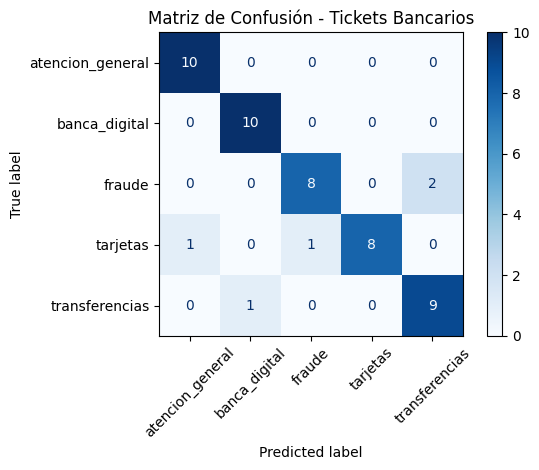

In [25]:
# Matriz de confusión
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=modelo.classes_,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Matriz de Confusión - Tickets Bancarios")
plt.tight_layout()
plt.show()

## Pruebas manuales con nuevos tickets

Se realizan pruebas adicionales utilizando tickets creados manualmente
que no forman parte del conjunto de entrenamiento ni del conjunto de prueba.

El objetivo es observar el comportamiento del modelo ante situaciones
similares a solicitudes reales de clientes.


In [26]:
# Pruebas
tickets_nuevos = [
    "Detecté una compra que yo no realicé y quiero reportarla",
    "Mi tarjeta fue rechazada cuando intenté pagar en una tienda",
    "No puedo iniciar sesión en la aplicación del banco",
    "Hice una transferencia pero el dinero todavía no llega al destinatario",
    "Quiero actualizar mi número de teléfono registrado"
]

# Transformar con el mismo TF-IDF
tickets_tfidf = tfidf.transform(tickets_nuevos)

# Realizar predicciones
predicciones = modelo.predict(tickets_tfidf)

# Mostrar resultados
for ticket, categoria in zip(tickets_nuevos, predicciones):
    print("Ticket:", ticket)
    print("Categoría predicha:", categoria)
    print("-" * 60)

Ticket: Detecté una compra que yo no realicé y quiero reportarla
Categoría predicha: fraude
------------------------------------------------------------
Ticket: Mi tarjeta fue rechazada cuando intenté pagar en una tienda
Categoría predicha: tarjetas
------------------------------------------------------------
Ticket: No puedo iniciar sesión en la aplicación del banco
Categoría predicha: banca_digital
------------------------------------------------------------
Ticket: Hice una transferencia pero el dinero todavía no llega al destinatario
Categoría predicha: transferencias
------------------------------------------------------------
Ticket: Quiero actualizar mi número de teléfono registrado
Categoría predicha: atencion_general
------------------------------------------------------------


In [27]:
resultados_manual = pd.DataFrame({
    "Ticket": tickets_nuevos,
    "Categoría esperada": [
        "fraude",
        "tarjetas",
        "banca_digital",
        "transferencias",
        "atencion_general"
    ],
    "Predicción": predicciones
})

resultados_manual["Resultado"] = (
    resultados_manual["Categoría esperada"]
    == resultados_manual["Predicción"]
)

resultados_manual

,Ticket,Categoría esperada,Predicción,Resultado
0,Detecté una compra que yo no realicé y quiero ...,fraude,fraude,True
1,Mi tarjeta fue rechazada cuando intenté pagar ...,tarjetas,tarjetas,True
2,No puedo iniciar sesión en la aplicación del b...,banca_digital,banca_digital,True
3,Hice una transferencia pero el dinero todavía ...,transferencias,transferencias,True
4,Quiero actualizar mi número de teléfono regist...,atencion_general,atencion_general,True


In [28]:
# Casos extremos
tickets_extremos = [
    "",
    "Tengo un problema",
    "Ayuda por favor",
    "Mi tarjeta tiene un cargo que no reconozco",
    "No puedo entrar a la app y además veo una transferencia que yo no hice"
]

tickets_extremos_tfidf = tfidf.transform(tickets_extremos)
predicciones_extremas = modelo.predict(tickets_extremos_tfidf)

resultados_extremos = pd.DataFrame({
    "Ticket": tickets_extremos,
    "Predicción": predicciones_extremas
})

resultados_extremos

,Ticket,Predicción
0,,atencion_general
1,Tengo un problema,atencion_general
2,Ayuda por favor,fraude
3,Mi tarjeta tiene un cargo que no reconozco,fraude
4,No puedo entrar a la app y además veo una tran...,transferencias


## Asignación de prioridad y área responsable

Una vez identificada la categoría del ticket mediante el modelo de
clasificación, se aplican reglas de negocio para determinar la prioridad
inicial y sugerir el área responsable.

Estas recomendaciones funcionan como apoyo al agente, quien mantiene
la decisión final sobre la gestión del incidente.

In [30]:
# Definimos las áreas
areas = {
    "fraude": "Prevención de Fraude",
    "tarjetas": "Atención de Tarjetas",
    "banca_digital": "Soporte Digital",
    "transferencias": "Operaciones Bancarias",
    "atencion_general": "Atención al Cliente"
}

In [31]:
# Definimos la prioridad
def obtener_prioridad(texto, categoria):
    texto = texto.lower()

    palabras_criticas = [
        "no reconozco",
        "robo",
        "robada",
        "fraude",
        "cargo no reconocido",
        "operación no reconocida"
    ]

    palabras_altas = [
        "bloqueada",
        "bloqueado",
        "no puedo entrar",
        "no puedo acceder",
        "rechazada",
        "rechazado"
    ]

    if categoria == "fraude" or any(p in texto for p in palabras_criticas):
        return "Crítica"

    elif any(p in texto for p in palabras_altas):
        return "Alta"

    elif categoria == "transferencias":
        return "Media"

    else:
        return "Baja"

In [32]:
# Función completa
def clasificar_ticket(texto):

    # Transformar texto
    texto_tfidf = tfidf.transform([texto])

    # Predecir categoría
    categoria = modelo.predict(texto_tfidf)[0]

    # Obtener prioridad
    prioridad = obtener_prioridad(texto, categoria)

    # Obtener área
    area = areas[categoria]

    return {
        "ticket": texto,
        "categoria": categoria,
        "prioridad": prioridad,
        "area": area
    }

In [33]:
# Prueba
ticket = "No reconozco una transferencia realizada desde mi cuenta"

resultado = clasificar_ticket(ticket)

print("RESULTADO DEL ANÁLISIS")
print("----------------------")
print("Ticket:", resultado["ticket"])
print("Categoría:", resultado["categoria"])
print("Prioridad:", resultado["prioridad"])
print("Área sugerida:", resultado["area"])

RESULTADO DEL ANÁLISIS
----------------------
Ticket: No reconozco una transferencia realizada desde mi cuenta
Categoría: transferencias
Prioridad: Crítica
Área sugerida: Operaciones Bancarias


In [34]:
tickets_prueba = [
    "No reconozco un cargo realizado con mi tarjeta",
    "Mi tarjeta está bloqueada y no puedo utilizarla",
    "No puedo entrar a la aplicación del banco",
    "Mi transferencia sigue pendiente",
    "Quiero actualizar mis datos personales"
]

for ticket in tickets_prueba:

    resultado = clasificar_ticket(ticket)

    print("Ticket:", resultado["ticket"])
    print("Categoría:", resultado["categoria"])
    print("Prioridad:", resultado["prioridad"])
    print("Área:", resultado["area"])
    print("-" * 60)

Ticket: No reconozco un cargo realizado con mi tarjeta
Categoría: fraude
Prioridad: Crítica
Área: Prevención de Fraude
------------------------------------------------------------
Ticket: Mi tarjeta está bloqueada y no puedo utilizarla
Categoría: tarjetas
Prioridad: Alta
Área: Atención de Tarjetas
------------------------------------------------------------
Ticket: No puedo entrar a la aplicación del banco
Categoría: banca_digital
Prioridad: Alta
Área: Soporte Digital
------------------------------------------------------------
Ticket: Mi transferencia sigue pendiente
Categoría: transferencias
Prioridad: Media
Área: Operaciones Bancarias
------------------------------------------------------------
Ticket: Quiero actualizar mis datos personales
Categoría: atencion_general
Prioridad: Baja
Área: Atención al Cliente
------------------------------------------------------------


## Guardado del modelo

Una vez entrenado y evaluado el clasificador, se almacenan el modelo de
Regresión Logística y el vectorizador TF-IDF.

Estos archivos permitirán reutilizar el modelo posteriormente desde la API
sin necesidad de realizar nuevamente el proceso de entrenamiento.

In [35]:
# Guardar ambos archivos
import joblib

joblib.dump(modelo, "modelo_tickets.joblib")
joblib.dump(tfidf, "vectorizador_tfidf.joblib")

print("Archivos guardados correctamente:")
print("- modelo_tickets.joblib")
print("- vectorizador_tfidf.joblib")

Archivos guardados correctamente:
- modelo_tickets.joblib
- vectorizador_tfidf.joblib


In [36]:
# Verificar
import os

archivos = [
    "modelo_tickets.joblib",
    "vectorizador_tfidf.joblib"
]

for archivo in archivos:
    if os.path.exists(archivo):
        print(f"OK - {archivo}")
    else:
        print(f"ERROR - {archivo}")

OK - modelo_tickets.joblib
OK - vectorizador_tfidf.joblib


In [37]:
# Prueba
modelo_cargado = joblib.load("modelo_tickets.joblib")
tfidf_cargado = joblib.load("vectorizador_tfidf.joblib")

ticket_prueba = "No reconozco un movimiento realizado desde mi cuenta"

ticket_transformado = tfidf_cargado.transform([ticket_prueba])

prediccion = modelo_cargado.predict(ticket_transformado)[0]

print("PRUEBA DEL MODELO GUARDADO")
print("--------------------------")
print("Ticket:", ticket_prueba)
print("Predicción:", prediccion)

PRUEBA DEL MODELO GUARDADO
--------------------------
Ticket: No reconozco un movimiento realizado desde mi cuenta
Predicción: fraude


In [38]:
# Descarga los archivos
from google.colab import files

files.download("modelo_tickets.joblib")
files.download("vectorizador_tfidf.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>